# **Milestone 6** | Planetary Weather Data Analysis

<div style="text-align: center;">
<img src="https://www.nasa.gov/wp-content/uploads/2023/04/nasa-logo-web-rgb.png" alt="NASA Logo" width="320"/>
</div>

## **Introduction**

In this Milestone, you'll role play as an intern at NASA, where you'll work to analyze weather data collected from a planetary rover. The dataset, `planet_weather.csv` contains atmospheric measurements from a planet in our solar system, but the planet's identity has not been disclosed. Your objective is to apply data inspection, cleaning, and analysis techniques to draw conclusions about the planet based on the provided weather data.


The dataset, located in the `datasets/` folder is called `planet_weather.csv`, and it contains the following information:

- **terrestrial_date**: Date on planet Earth, captured as `yyyy-mm-dd`.

- **sol**: number of elapsed planetary days since beginning measurement.

- **ls**: solar longitude. 0: fall equinox. 90: winter solstice. 180: spring equinox. 270: summer solstice.

- **month**: the month number on the mystery planet.

- **min_temp**: the minimum temperature, in Celsius, during a single day.

- **pressure**: atmospheric pressure, in Pascals

- **wind_speed**: average wind speed, in meters per second.

- **atmo_opacity**: atmospheric opacity.


To start, import both the pandas and plotly.express libraries, and load the data into a DataFrame.


In [23]:
# Import pandas and plotly.express libraries
import pandas as pd
import plotly.express as px

In [24]:
# Load planet_weather.csv data from datasets folder
df = pd.read_csv("datasets/planet_weather.csv")

## **Task 1** - Data Inspection 🔍

Before analyzing anything, it's essential to understand the structure and contents of your dataset. You'll start by previewing the data and checking for missing values or unusual patterns.


In [4]:
# Preview the data
df.sample(5)

,id,terrestrial_date,sol,ls,month,min_temp,max_temp,pressure,wind_speed,atmo_opacity
1226,668,2014-08-22,726,182,Month 7,-75.0,1.0,766.0,NaN,Sunny
1003,891,2015-04-18,959,327,Month 11,-78.0,-4.0,846.0,NaN,Sunny
16,1877,2018-02-11,1961,127,Month 5,-77.0,-21.0,740.0,NaN,Sunny
168,1728,2017-09-07,1809,57,Month 2,-80.0,-25.0,884.0,NaN,Sunny
1127,767,2014-12-01,825,243,Month 9,-67.0,1.0,914.0,NaN,Sunny


**1.** How many rows and columns are there in the dataset?

In [6]:
# Dataset rows and columns
rows, columns = df.shape[0], df.shape[1]
print(f"Num Rows: {rows}\nNum Columns: {columns}")

Num Rows: 1894
Num Columns: 10


**2.** What are the names of all the columns?

In [11]:
# Dataset columns
print(df.columns)

Index(['id', 'terrestrial_date', 'sol', 'ls', 'month', 'min_temp', 'max_temp',
       'pressure', 'wind_speed', 'atmo_opacity'],
      dtype='object')


**3.** What is the data type of each column?

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">There are a few ways to do this! Both <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">.info()</code> and <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">.dtypes</code> will work.</span>
</div>

In [14]:
# Data types of each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1894 entries, 0 to 1893
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                1894 non-null   int64  
 1   terrestrial_date  1894 non-null   object 
 2   sol               1894 non-null   int64  
 3   ls                1894 non-null   int64  
 4   month             1894 non-null   object 
 5   min_temp          1867 non-null   float64
 6   max_temp          1867 non-null   float64
 7   pressure          1867 non-null   float64
 8   wind_speed        0 non-null      float64
 9   atmo_opacity      1894 non-null   object 
dtypes: float64(4), int64(3), object(3)
memory usage: 148.1+ KB


**4.** How many null values are there in each column? For each column, sum up the number of null values.

In [16]:
# Null values in each column
df.isnull().sum()

id                     0
terrestrial_date       0
sol                    0
ls                     0
month                  0
min_temp              27
max_temp              27
pressure              27
wind_speed          1894
atmo_opacity           0
dtype: int64

**5.** Provide a statistical summary of the DataFrame.

In [17]:
# Statistical summary of the DataFrame
df.describe()

,id,sol,ls,min_temp,max_temp,pressure,wind_speed
count,1894.000000,1894.000000,1894.000000,1867.000000,1867.000000,1867.000000,0.0
mean,948.372228,1007.930306,169.180570,-76.121050,-12.510445,841.066417,NaN
std,547.088173,567.879561,105.738532,5.504098,10.699454,54.253226,NaN
min,1.000000,1.000000,0.000000,-90.000000,-35.000000,727.000000,NaN
25%,475.250000,532.250000,78.000000,-80.000000,-23.000000,800.000000,NaN
50%,948.500000,1016.500000,160.000000,-76.000000,-11.000000,853.000000,NaN
75%,1421.750000,1501.750000,259.000000,-72.000000,-3.000000,883.000000,NaN
max,1895.000000,1977.000000,359.000000,-62.000000,11.000000,925.000000,NaN


<div style="border: 3px solid #30EE99; background: #f0fff4; padding: 12px 16px; border-radius: 6px;">
  <p style="font-size: 12px; font-weight: 700; color: black; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 8px 0;">Try this AI Prompt</p>
  <p style="font-size: 14px; color: #1a1a1a; margin: 0;">Summarize key things a data analyst should look for when reviewing <code style="background: #c8fce6; padding: 2px 5px; border-radius: 3px; font-size: 14px; color: #0F6E56;">.shape</code>, <code style="background: #c8fce6; padding: 2px 5px; border-radius: 3px; font-size: 14px; color: #0F6E56;">.info()</code>, and <code style="background: #c8fce6; padding: 2px 5px; border-radius: 3px; font-size: 14px; color: #0F6E56;">.describe()</code> outputs from a new dataset.</p>
</div>

**QUESTION:** Based on the dataset's shape, column types, and statistical summary, what initial observations can you make about the data's structure, completeness, and potential quality issues?
<div style="background: #d0f0f8; padding: 5px 12px; border-radius: 0 0 6px 6px;">
  <span style="font-size: 12px; font-weight: 700; color: #1a6b8a; letter-spacing: 0.06em; text-transform: uppercase;">Type your answer below</span>
</div>

I can see that wind speed wasn't calculated as the datapoints are incomplete so I am assuming there was an error in wind speed measurements. I can also see that the max temperature is below freezing point. There are some null values in pressure, min temp and max temp but this may be during days or months where the system wasn't recording those specific values. 

## **Task 2** - Data Cleaning
Now that you’ve inspected the data, your next step is to check for any columns that might need to be cleaned or removed.

**1.** Are there any columns with mostly missing values? Perhaps the wind speed sensor was broken! Remove this column from the dataframe.

In [26]:
# Delete wind_speed column, which is filled with null values
df = df.drop(columns=["wind_speed"])

**2A.** Take a close look at the `atmo_opacity` column. How many unique values are there, and how frequently does each appear?

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">Both <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">.nunique()</code> and <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">.value_counts()</code> will work here!</span>
</div>

In [28]:
# How many unique values are there, and how frequently does each appear?
df["atmo_opacity"].value_counts()

Sunny    1891
--          3
Name: atmo_opacity, dtype: int64

**2B.** The atmosphere sensors seem to have been faulty and did not capture accurate data. Drop the `atmo_opacity` column.

In [29]:
# Drop the atmo_opacity column
df = df.drop(columns=["atmo_opacity"])

## **Task 3** - Data Analysis & Visualization

Let’s explore trends in the planetary weather using groupings and charts. This will help you uncover seasonal patterns and key environmental characteristics of the mystery planet.

You’ll need to use the `.groupby()` method here to analyze how temperature and pressure vary across months. Store your grouped results in new DataFrames to make them easier to visualize.

**1.** How many months are there on this planet?

In [33]:
# Number of unique months
df.groupby('month').nunique()

,id,terrestrial_date,sol,ls,min_temp,max_temp,pressure
month,,,,,,,
Month 1,176,176,176,30,11,19,51
Month 10,116,116,116,30,13,16,46
Month 11,145,145,145,30,12,16,42
Month 12,166,166,166,30,12,18,25
Month 2,182,182,182,30,11,15,39
Month 3,194,194,194,30,14,12,66
Month 4,194,194,194,30,13,18,97
Month 5,149,149,149,30,12,25,50
Month 6,153,153,153,30,11,26,32


**2A.** What is the average minimum temperature for each month?

In [51]:
# Average min_temp each month
df2 = df.groupby('month')['min_temp'].mean()
print(df2)

month
Month 1    -77.160920
Month 10   -71.982143
Month 11   -71.985507
Month 12   -74.451807
Month 2    -79.932584
Month 3    -83.307292
Month 4    -82.747423
Month 5    -79.308725
Month 6    -75.299320
Month 7    -72.281690
Month 8    -68.382979
Month 9    -69.171642
Name: min_temp, dtype: float64


**2B.** Using your grouped results above, plot a bar chart of the average minimum temperature by month.

<div style="border: 3px solid #30EE99; background: #f0fff4; padding: 12px 16px; border-radius: 6px;">
  <p style="font-size: 12px; font-weight: 700; color: black; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 8px 0;">Try this AI Prompt</p>
  <p style="font-size: 14px; color: #1a1a1a; margin: 0;">In my Plotly Express bar chart, the x-axis shows months but they're sorted alphabetically (Month 1, Month 10, Month 11, etc.) instead of Month 1 – Month 12 order. How can I replot my data so that the x-axis sorts numerically by month?</p>
</div>

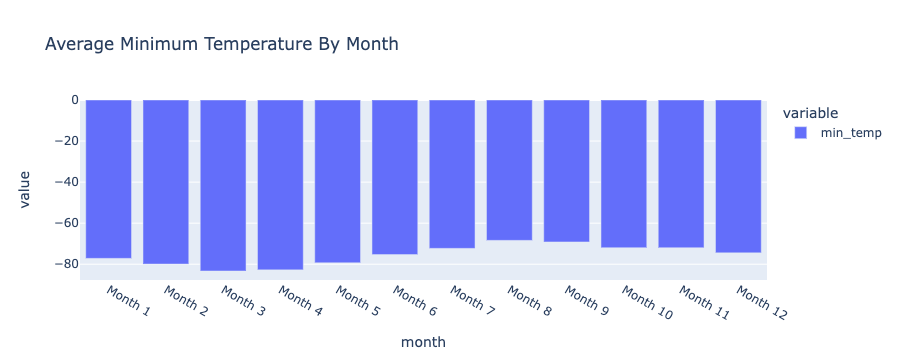

In [52]:
# Bar chart of the average min_temp by month
px.bar(
    df2,
    title='Average Minimum Temperature By Month',
    category_orders={'month': ['Month 1', 'Month 2', 'Month 3', 'Month 4', 'Month 5', 'Month 6', 'Month 7', 'Month 8', 'Month 9', 'Month 10', 'Month 11', 'Month 12']}
)

**QUESTION:** Based on the minimum temperature, what is the coldest month? What is the warmest month?
<div style="background: #d0f0f8; padding: 5px 12px; border-radius: 0 0 6px 6px;">
  <span style="font-size: 12px; font-weight: 700; color: #1a6b8a; letter-spacing: 0.06em; text-transform: uppercase;">Type your answer below</span>
</div>

The coldest month is Month 3 and the warmest month is Month 8

**3A.** What is the average pressure for each month?

In [53]:
# What is the average pressure for each month?
df3 = df.groupby('month')['pressure'].mean()
print(df3)

month
Month 1     862.488506
Month 10    887.312500
Month 11    857.014493
Month 12    842.156627
Month 2     889.455056
Month 3     877.322917
Month 4     806.329897
Month 5     748.557047
Month 6     745.054422
Month 7     795.105634
Month 8     873.829787
Month 9     913.305970
Name: pressure, dtype: float64


**3B.** Using your grouped results above, plot a bar chart of the average atmospheric pressure by month.

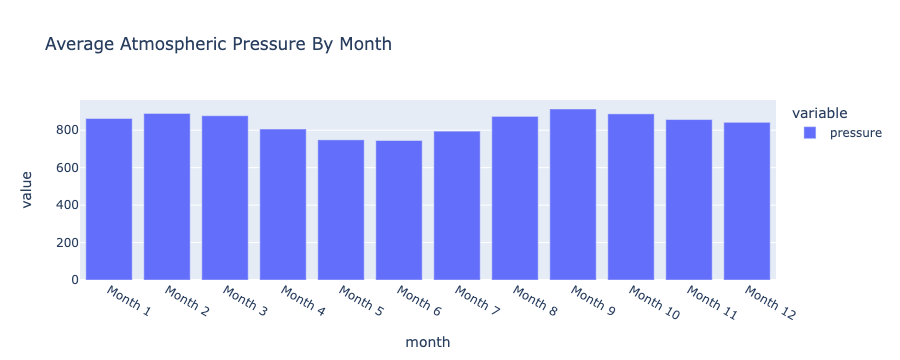

In [54]:
# Bar chart of the average atmospheric pressure by month
px.bar(
    df3,
    title='Average Atmospheric Pressure By Month',
    category_orders={'month': ['Month 1', 'Month 2', 'Month 3', 'Month 4', 'Month 5', 'Month 6', 'Month 7', 'Month 8', 'Month 9', 'Month 10', 'Month 11', 'Month 12']}
)

**4.** Plot a line chart of the daily atmospheric pressure by terrestrial date.

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Note</p>
  <span style="font-size: 14px; color: #1a1a1a;">You do not need to modify the dataframe or group any data! Just use the original data.</span>
</div>

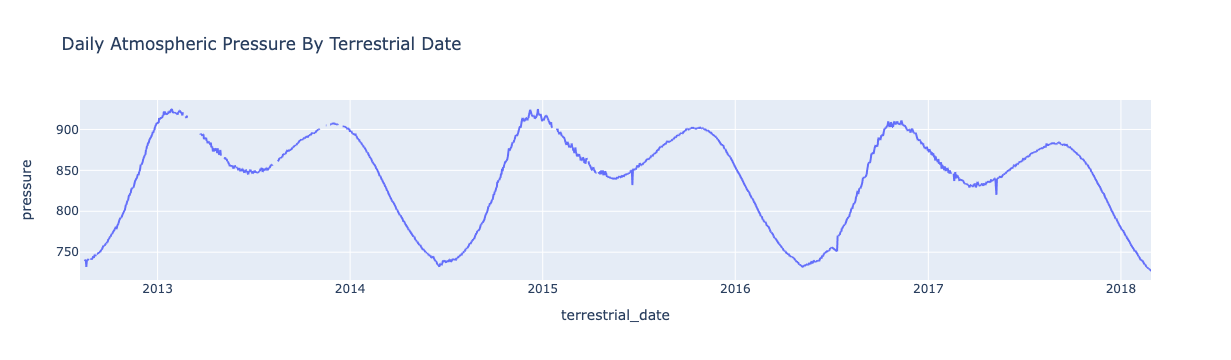

In [48]:
# Plot a line chart of the daily atmospheric pressure by terrestrial date
px.line(
    df,
    x='terrestrial_date',
    y='pressure',
    title='Daily Atmospheric Pressure By Terrestrial Date'

)

**5.** Plot a line chart of the daily minimum temp.

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Note</p>
  <span style="font-size: 14px; color: #1a1a1a;">You do not need to modify the dataframe or group any data! Just use the original data.</span>
</div>

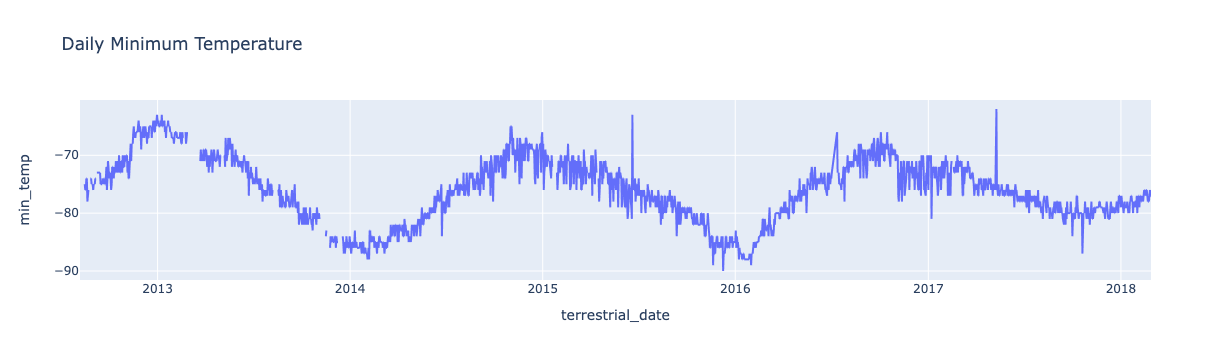

In [50]:
# Plot a line chart of the daily minimum temp
px.line(
    df,
    x='terrestrial_date',
    y='min_temp',
    title='Daily Minimum Temperature'

)

**6.** Based on this information, approximately how many Earth days are there in a year on this planet?

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">To do this, get an approximate range for how long a "year" is on this planet by looking at the plot of either the atmospheric pressure or the temperature by day. Use the visualization to get a <em>rough estimate</em> between matching "peaks".</span>
</div>

<div style="background: #d0f0f8; padding: 5px 12px; border-radius: 0 0 6px 6px;">
  <span style="font-size: 12px; font-weight: 700; color: #1a6b8a; letter-spacing: 0.06em; text-transform: uppercase;">Type your answer below</span>
</div>

675 days since its approximately a 1.85 years which is an approximation visually between each peak

**7.** What is the identity of the planet? Go to [this website](https://spaceplace.nasa.gov/years-on-other-planets/en/) and see what planet this lines up with!

<div style="background: #d0f0f8; padding: 5px 12px; border-radius: 0 0 6px 6px;">
  <span style="font-size: 12px; font-weight: 700; color: #1a6b8a; letter-spacing: 0.06em; text-transform: uppercase;">Type your answer below</span>
</div>

Mars

### 🚀 **Congratulations!**
You made your first extra-terrestrial discovery!

<div style="text-align: left;">
<img src="https://media.giphy.com/media/5ndfKr0Nv92LkWrKpU/giphy.gif" alt="gif of clapping" width="320"/>
</div>

## **LevelUp** 🌟 

Earlier in the milestone you investigated how many months were in our mystery planet. Unfortunately, the answer (12) was not very satisfying. This is because there is no standard calendar for the mystery planet. When the data was collected, they used 12 "months" though each month is longer than a typical Earth month. Let's investigate!

First, filter your dataset so that you are only looking at any `terrestrial_date` before 2014.

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint</p>
  <span style="font-size: 14px; color: #1a1a1a;">Since <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">terrestrial_date</code> is a <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">string</code> data type, this is simply checking for all values that satisfy the condition <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">< '2014'</code> (don't forget the quotation marks!)</span>
</div>

In [ ]:
# Filter to all values where terrestrial_date is before 2014 and store it in a new variable

# Show dataframe


<div style="border-left: 4px solid #f8c43e; background: #fff3c1; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #a67c00; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Answer Check</p>
  <span style="font-size: 14px; color: #1a1a1a;">If done correctly, you will have a dataframe with <strong>441 rows</strong>.</span>
</div>

Lastly, for each month in the dataframe, return both the `min` value and the `max` value of the `terrestrial_date` field.

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint 1</p>
  <span style="font-size: 14px; color: #1a1a1a;">You'll need to use <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">.groupby()</code></span>
</div>

<br>

<div style="border-left: 4px solid #b67ae5; background: #f9f1ff; padding: 10px 14px; border-radius: 0 6px 6px 0;">
  <p style="font-size: 12px; font-weight: 700; color: #6a3fa3; letter-spacing: 0.06em; text-transform: uppercase; margin: 0 0 6px 0;">Hint 2</p>
  <span style="font-size: 14px; color: #1a1a1a;">In the dictionary for your <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">.agg()</code> function, pass a list of values. e.g. <code style="background: #e4c8fc; padding: 1px 4px; border-radius: 3px; font-size: 14px;">{col_to_check: [func1, func2]}</code>. Remember to use the appropriate values / variables from the dataframe and the desired functions.</span>
</div>

In [ ]:
# For each month, calculate the minimum AND maximum terrestrial_date


**QUESTION:** How many Earth days, roughly, are there in each "month" on the mystery planet? Does that line up with what you expected now that you know its identity?

<div style="background: #d0f0f8; padding: 5px 12px; border-radius: 0 0 6px 6px;">
  <span style="font-size: 12px; font-weight: 700; color: #1a6b8a; letter-spacing: 0.06em; text-transform: uppercase;">Type your answer below</span>
</div>

➡️ Double-click (or enter) to edit ⬅️